# 📑 PageIndex - Vectorless RAG 

### Reasoning-based RAG with No Vector DB, No Chunking


### 🧠 What You'll Learn

| # | Topic |
|---|-------|
| 1 | Why Vector RAG fails on professional documents |
| 2 | How PageIndex builds a tree index from a PDF |
| 3 | LLM Tree Search — reasoning over structure |
| 4 | Full end-to-end Vectorless RAG pipeline |
| 5 | Expert-guided retrieval (domain knowledge injection) |
| 6 | Chat API — zero LLM setup |
| 7 | Self-hosted open-source option |


### 🔑 Key Concepts

> **Traditional RAG** → chunk → embed → cosine similarity → retrieve  

> **PageIndex RAG** → build tree → LLM reasons over tree → retrieve exact sections

**The problem with vector RAG:**  `Similarity ≠ Relevance`  
A chunk about "market conditions" may score higher than the actual answer section just because it shares more words with your query.


### **When Table of Content (TOC ) is available**

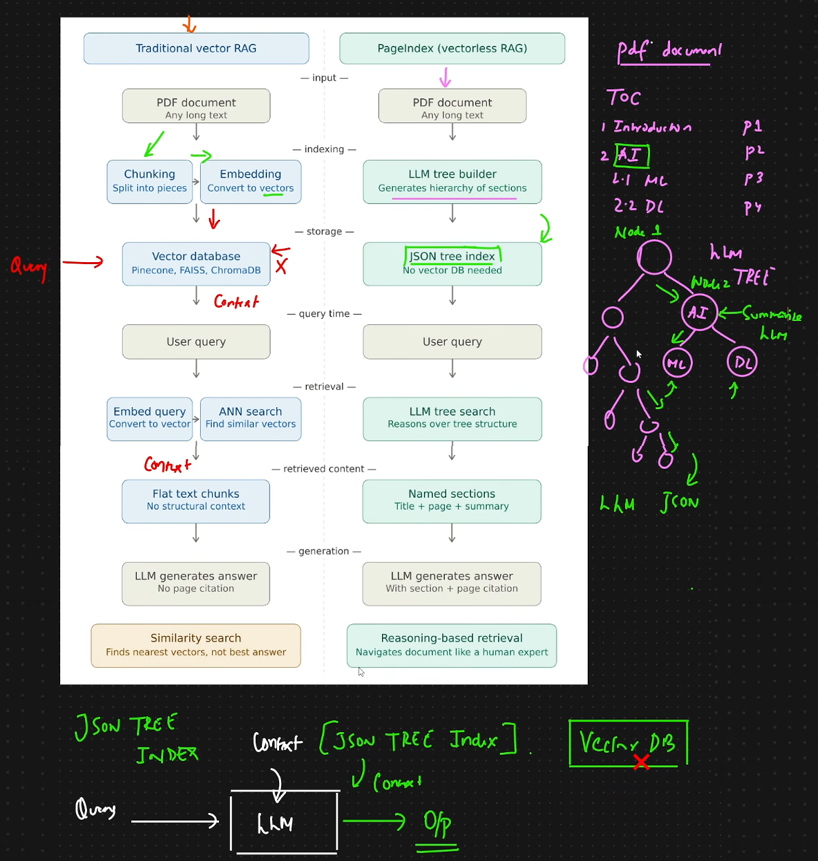

### **When Table of Content (TOC ) is Unavailable**

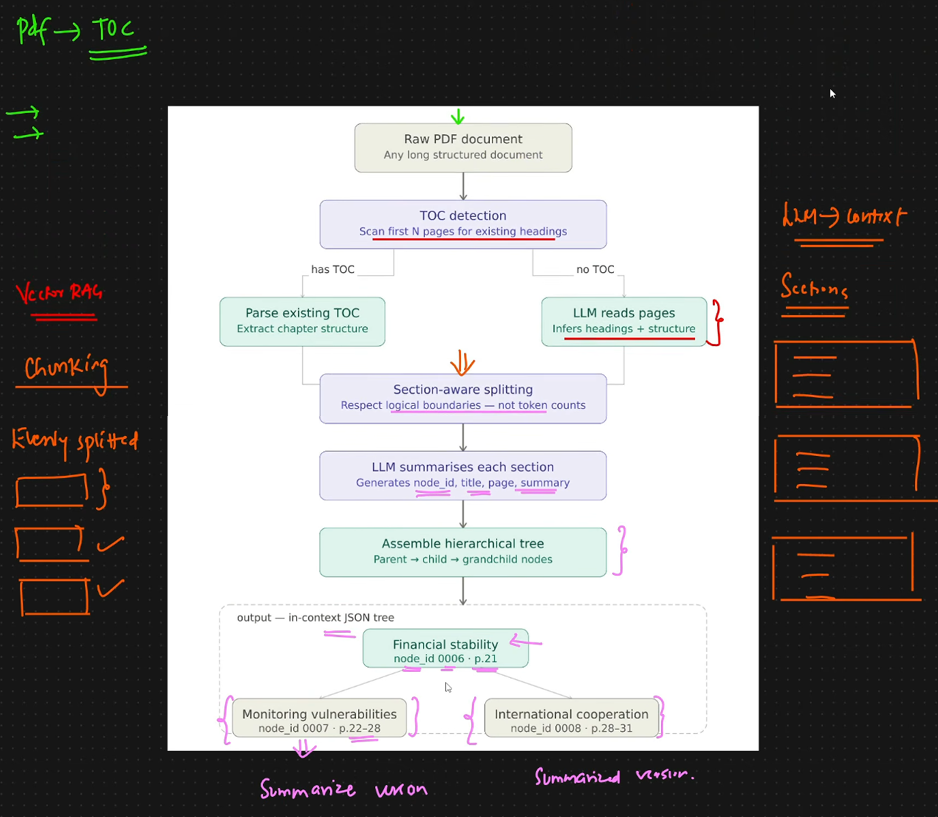



### **Vectorless RAG Retrieval Pipeline**

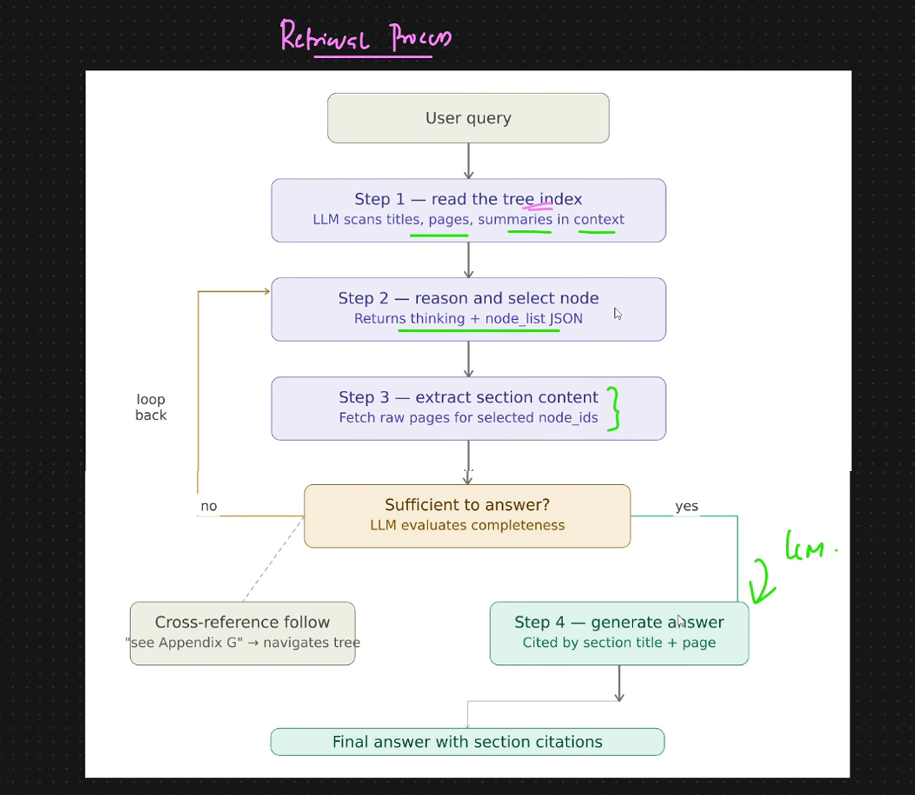

### Can also use Claude but we will use PageIndex repository

---
## 📦 Section 1: Install & Setup

**What we do here:**
- Install PageIndex SDK + OpenAI
- Load API keys from `.env`
- Initialize both clients

> 🔑 Get your **PageIndex API key** from: https://dash.pageindex.ai/api-keys  
> 🔑 Get your **GEMINI API key** from: https://aistudio.google.com/

model("google_genai:gemini-3.5-flash")


In [2]:
# Install required packages
%pip install -U pageindex google_genai python-dotenv

Note: you may need to restart the kernel to use updated packages.


g:\SAKSHAM RAJ\Courses\Agentic AI by Krish Naik\vectorlessRAG\.venv\Scripts\python.exe: No module named pip


In [ ]:
# ── Create a .env file (run this once) ──────────────────────────────────────
# Uncomment and fill in your keys, then run this cell ONCE

# env_content = """
# PAGEINDEX_API_KEY=your_pageindex_key_here
# GEMINI_API_KEY=your_gemini_key_here
# """
# with open(".env", "w") as f:
#     f.write(env_content.strip())
# print("✅ .env file created")

In [5]:
import os, json, time
from dotenv import load_dotenv

load_dotenv()

PAGEINDEX_API_KEY = os.getenv("PAGEINDEX_API_KEY")
GEMINI_API_KEY    = os.getenv("GOOGLE_API_KEY")
# GROQ_API_KEY      = os.getenv("GROQ_API_KEY")

print("PageIndex key loaded:", "✅" if PAGEINDEX_API_KEY else "❌ Missing!")
print("Gemini key loaded:   ", "✅" if GEMINI_API_KEY    else "❌ Missing!")
# print("Groq key loaded:   ", "✅" if GROQ_API_KEY      else "❌ Missing!")

PageIndex key loaded: ✅
Gemini key loaded:    ✅


In [6]:
from pageindex import PageIndexClient
from google import genai
from groq import Groq

pi_client = PageIndexClient(api_key=PAGEINDEX_API_KEY)
print("✅ PageIndex client ready")

gemini_client = genai.Client(api_key=GEMINI_API_KEY)
print("✅ GEMINI client ready")

# groq_client = Groq(api_key=GROQ_API_KEY)
# print("✅ GROQ client ready")

✅ PageIndex client ready
✅ GEMINI client ready


---
## 🌲 Section 2: Upload & Index a PDF

**What happens here:**
1. Upload your PDF to the PageIndex cloud
2. PageIndex uses an LLM to read the document structure
3. Builds a hierarchical **tree index** (like a smart Table of Contents)
4. Returns a `doc_id` for all future operations

**Why NO chunking?**  
Instead of cutting the document into arbitrary 500-token pieces, PageIndex respects the document's natural section boundaries — chapters, sub-sections, paragraphs — as the author intended.


In [ ]:
# ── Upload your PDF ─────────────────────────────────────────────────────────
# Great candidates: Annual reports, research papers, legal docs, textbooks

PDF_PATH = "G:\\SAKSHAM RAJ\\Courses\\Agentic AI by Krish Naik\\vectorlessRAG\\Constitution of India.pdf"   # pdf file path
# Uploaded the Constitution of India PDF to PageIndex

print(f"📤 Uploading: {PDF_PATH}")
result = pi_client.submit_document(PDF_PATH)
doc_id = result["doc_id"]

print(f"✅ Uploaded!")
print(f"📋 Document ID: {doc_id}")
print("   (Save this ID — you'll use it throughout the notebook)")

In [ ]:
# ── Poll until processing is complete ───────────────────────────────────────
# PageIndex builds the tree asynchronously.
# For a 400-page PDF this approximately takes 30 seconds.

print("⏳ Building tree index...")
print("   (This runs once per document — the index is cached for reuse)")

# read every page of the PDF and build a tree index
while True:
    status_result = pi_client.get_document(doc_id)
    status = status_result.get("status")
    print(f"   Status: {status}")
    
    if status == "completed":
        print("\n✅ Tree index ready!")
        break
    elif status == "failed":
        print("\n❌ Processing failed. Check your PDF format.")
        break
    
    time.sleep(5)

⏳ Building tree index...
   (This runs once per document — the index is cached for reuse)
   Status: processing
   Status: processing
   Status: processing
   Status: processing
   Status: processing
   Status: completed

✅ Tree index ready!


---
## 🔍 Section 3: Inspect the Tree Structure

**What the tree looks like:**

```
Document
├── Introduction (pages 1-3)
│   └── Background (pages 1-2)
├── Financial Stability (pages 21-31)
│   ├── Monitoring Vulnerabilities (pages 22-28)
│   └── International Cooperation (pages 28-31)
└── Conclusion (pages 45-47)
```

Each node has:
- `node_id` — unique ID used during retrieval
- `title` — section heading
- `page_index` — page number in original PDF
- `text` — section summary (when `node_summary=True`)
- `nodes` — child sections (nested)

**This structure is what the LLM reasons over during retrieval.**


In [13]:
doc_id = "pi-cmwdtsk1n00010bp9lg5fprli"

In [14]:
# ── Fetch the full tree ─────────────────────────────────────────────────────
tree_result  = pi_client.get_tree(doc_id, node_summary=True)
pageindex_tree = tree_result.get("result", [])

print(f"📊 Top-level sections: {len(pageindex_tree)}")
print("\n🌲 Raw tree (first node):")
print(json.dumps(pageindex_tree[0] if pageindex_tree else {}, indent=2))

📊 Top-level sections: 1

🌲 Raw tree (first node):
{
  "title": "\u092d\u093e\u0930\u0924 \u0915\u093e \u0938\u0902\u0935\u093f\u0927\u093e\u0928",
  "node_id": "0000",
  "start_index": 1,
  "end_index": 402,
  "summary": "\u092f\u0939 \u0916\u0902\u0921 \u092d\u093e\u0930\u0924 \u0915\u0947 \u0938\u0902\u0935\u093f\u0927\u093e\u0928 \u0915\u0947 \u092a\u094d\u0930\u093e\u0930\u0902\u092d\u093f\u0915 \u0935\u093f\u0935\u0930\u0923 \u0914\u0930 \u092a\u0930\u093f\u091a\u092f \u0938\u0947 \u0938\u0902\u092c\u0902\u0927\u093f\u0924 \u0939\u0948, \u091c\u093f\u0938\u092e\u0947\u0902 10 \u0938\u093f\u0924\u092e\u094d\u092c\u0930, 2026 \u0924\u0915 \u0915\u0947 \u0938\u0902\u0936\u094b\u0927\u0928\u094b\u0902 (106\u0935\u0947\u0902 \u0938\u0902\u0936\u094b\u0927\u0928, 2023 \u0924\u0915) \u0915\u0947 \u0905\u0928\u0941\u0938\u093e\u0930 \u0935\u093f\u0927\u093f \u0914\u0930 \u0928\u094d\u092f\u093e\u092f \u092e\u0902\u0924\u094d\u0930\u093e\u0932\u092f \u0926\u094d\u0935\u093e\u0930\u093e \u0

In [15]:
# ── Pretty-print the full tree ───────────────────────────────────────────────
def print_tree(nodes, indent=0):
    """Recursively print tree titles for a visual overview."""
    for node in nodes:
        prefix = "  " * indent + ("└─ " if indent > 0 else "")
        page   = node.get("page_index", "?")
        print(f"{prefix}[{node['node_id']}] {node['title']}  (p.{page})")
        if node.get("nodes"):
            print_tree(node["nodes"], indent + 1)

print("📚 Full Document Structure:\n")
print_tree(pageindex_tree)

📚 Full Document Structure:

[0000] भारत का संविधान  (p.?)
  └─ [0001] भारत का संविधान (intro)  (p.?)
  └─ [0002] THE CONSTITUTION OF INDIA  (p.?)
    └─ [0003] THE CONSTITUTION OF INDIA (intro)  (p.?)
    └─ [0004] PREFACE  (p.?)
      └─ [0005] PREFACE (intro)  (p.?)
      └─ [0006] LIST OF ABBREVIATIONS USED  (p.?)
      └─ [0007] THE CONSTITUTION OF INDIA  (p.?)
        └─ [0008] Constitution of India Contents: Parts I to V  (p.?)
        └─ [0009] Table of Contents: Executive, Parliament, Judiciary, and Comptroller and Auditor-General of India  (p.?)
        └─ [0010] Table of Contents: Supreme Court, Comptroller and Auditor-General, and the States  (p.?)
        └─ [0011] Constitution of India - Contents: Judiciary, Local Governance, Union Territories, and Centre-State Relations  (p.?)
        └─ [0012] Table of Contents: Relations, Finance, Trade, Services, and Tribunals  (p.?)
        └─ [0013] Constitution of India - Table of Contents (Part XIV to Part XXI)  (p.?)
        └─ [0

In [16]:
# ── Count total nodes ────────────────────────────────────────────────────────
def count_nodes(nodes):
    total = len(nodes)
    for n in nodes:
        if n.get("nodes"):
            total += count_nodes(n["nodes"])
    return total

total = count_nodes(pageindex_tree)
print(f"🔢 Total nodes in tree: {total}")
print("   Each node = one retrievable section of the document")

🔢 Total nodes in tree: 109
   Each node = one retrievable section of the document


---
## 🧠 Section 4: LLM Tree Search — The Core of PageIndex

**This is where PageIndex fundamentally differs from vector RAG.**

### Vector RAG retrieval:
```
query → embed → cosine_similarity(query_vec, all_chunk_vecs) → top-k chunks
```
*Problem: finds what's similar, not what's relevant*

### PageIndex retrieval:
```
query + tree → LLM reasons → "node 0007 and 0008 contain the answer"
```
*Advantage: LLM understands document structure, context, and intent*

**The LLM acts like a human expert scanning a Table of Contents.**


In [17]:
import json
from google.genai import types

# ── LLM Tree Search Function ─────────────────────────────────────────────────

def llm_tree_search(query: str, tree: list, model: str = "gemini-3.5-flash-lite") -> dict:
    """
    Core PageIndex retrieval:
    Sends the query + document tree to Gemini.
    Gemini reasons over the structure and returns relevant node_ids.
    
    Returns: dict with 'thinking' (reasoning) and 'node_list' (node IDs)
    """
    
    # Compress tree to save tokens — only send titles + short summaries
    def compress(nodes):
        out = []
        for n in nodes:
            entry = {
                "node_id": n["node_id"],
                "title":   n["title"],
                "page":    n.get("page_index", "?"),
                "summary": n.get("text", "")[:150]  # first 150 chars
            }
            if n.get("nodes"):
                entry["children"] = compress(n["nodes"])
            out.append(entry)
        return out
    
    compressed_tree = compress(tree)
    
    prompt = f"""You are given a query and a document's tree structure (like a Table of Contents).
Your task: identify which node IDs most likely contain the answer to the query.
Think step-by-step about which sections are relevant.

Query: {query}

Document Tree:
{json.dumps(compressed_tree, indent=2)}

Reply ONLY in this exact JSON format:
{{
  "thinking": "<your step-by-step reasoning>",
  "node_list": ["node_id1", "node_id2"]
}}"""

    response = gemini_client.models.generate_content(
        model=model,
        contents=prompt,
        config=types.GenerateContentConfig(
            response_mime_type="application/json"
        ),
    )
    
    return json.loads(response.text)

In [18]:
# ── Test with a sample query ─────────────────────────────────────────────────
query = "Which sections of the Constitution of India discuss Fundamental Rights and their enforcement?"

print(f"🔍 Query: {query}\n")
result = llm_tree_search(query, pageindex_tree)

print("🧠 LLM Reasoning:")
print(result.get("thinking", "N/A"))
print()
print("🎯 Selected Node IDs:", result.get("node_list", []))

🔍 Query: Which sections of the Constitution of India discuss Fundamental Rights and their enforcement?

🧠 LLM Reasoning:
The user is asking for the sections of the Constitution of India that discuss 'Fundamental Rights and their enforcement'. Looking at the document tree structure, 'Part III' of the Constitution covers 'Fundamental Rights'. Specifically, node IDs 0018, 0019, and 0020 cover Part III (Fundamental Rights, Right to Freedom, Exploitation, Religion, Culture, Education, Property Savings, and Fundamental Remedies). Additionally, node 0020 explicitly mentions 'Fundamental Remedies' which relates to enforcement.

🎯 Selected Node IDs: ['0018', '0019', '0020']


---
## ⚙️ Section 5: Full End-to-End RAG Pipeline

**3 steps:**
1. **Tree Search** → LLM picks relevant `node_ids`
2. **Retrieve** → Fetch the actual section content from those nodes  
3. **Generate** → LLM writes a grounded answer with page citations

**What makes this better than vector RAG:**
- Retrieved content has titles + page numbers (traceable)
- LLM can cite exactly *which section* the answer comes from
- No hallucination from irrelevant chunks


In [19]:
# ── Helper: Find nodes by ID ─────────────────────────────────────────────────

def find_nodes_by_ids(tree: list, target_ids: list) -> list:
    """Recursively walk the tree and collect nodes matching target_ids."""
    found = []
    for node in tree:
        if node["node_id"] in target_ids:
            found.append(node)
        if node.get("nodes"):
            found.extend(find_nodes_by_ids(node["nodes"], target_ids))
    return found

In [44]:
# ── Generate answer from retrieved nodes ─────────────────────────────────────

def generate_answer(query: str, nodes: list, model: str = "gemini-3.5-flash-lite") -> str:
    """
    Takes retrieved nodes as context and generates a grounded answer.
    Instructs the LLM to cite section titles and page numbers.
    """
    if not nodes:
        return "⚠️ No relevant sections found in the document."
    
    # Build context string from retrieved nodes
    context_parts = []
    for node in nodes:
        context_parts.append(
            f"[Section: '{node['title']}' | Page {node.get('page_index', '?')}]\n"
            f"{node.get('text', 'Content not available.')}"
        )
    context = "\n\n---\n\n".join(context_parts)
    
    prompt = f"""You are an expert document analyst.
Answer the question using ONLY the provided context.
For every claim you make, cite the section title and page number in parentheses.
Be concise and precise but thorough in minimum of 3 sentences.

Question: {query}

Context:
{context}

Answer:"""
    
    response = gemini_client.models.generate_content(
        model=model,
        contents=prompt,
        config=types.GenerateContentConfig(
            response_mime_type="application/json"
        ),
    )
    
    return response.text

In [21]:
# ── The complete Vectorless RAG function ─────────────────────────────────────

def vectorless_rag(query: str, tree: list, verbose: bool = True) -> str:
    """
    Full end-to-end PageIndex RAG pipeline:
    
    Step 1: LLM Tree Search  → finds relevant node_ids
    Step 2: Node Retrieval   → fetches section content
    Step 3: Answer Generation → produces cited answer
    """
    if verbose:
        print(f"{'='*55}")
        print(f"🔍 Query: {query}")
        print(f"{'='*55}")
    
    # Step 1: Tree Search
    search_result  = llm_tree_search(query, tree)
    node_ids       = search_result.get("node_list", [])
    
    if verbose:
        print(f"\n🧠 Reasoning: {search_result.get('thinking', '')[:200]}...")
        print(f"🎯 Retrieved node IDs: {node_ids}")
    
    # Step 2: Retrieve nodes
    nodes = find_nodes_by_ids(tree, node_ids)
    
    if verbose:
        print(f"📄 Sections found: {[n['title'] for n in nodes]}")
    
    # Step 3: Generate answer
    answer = generate_answer(query, nodes)
    
    if verbose:
        print(f"\n📝 Answer:\n{answer}")
    
    return answer

In [22]:
# ── Run the full pipeline ────────────────────────────────────────────────────
answer = vectorless_rag(
    query="Which sections of the Constitution of India discuss Fundamental Rights and their enforcement?",
    tree=pageindex_tree
)

🔍 Query: Which sections of the Constitution of India discuss Fundamental Rights and their enforcement?

🧠 Reasoning: The user is asking for sections of the Constitution of India that discuss 'Fundamental Rights and their enforcement'. Looking at the document tree, Fundamental Rights are covered in Part III of the Co...
🎯 Retrieved node IDs: ['0018', '0019', '0020']
📄 Sections found: ['Fundamental Rights: Right to Freedom and Protection of Personal Liberties', 'Fundamental Rights: Exploitation, Religion, Culture, Education, and Property Savings', 'Saving of Certain Laws, Fundamental Remedies, and Directive Principles of State Policy']

📝 Answer:
[
  {
    "sections": "Right to Constitutional Remedies",
    "page": 19
  }
]


In [ ]:
# ── Test with multiple queries that is not in the index ───────────────────────────────────────────────
test_queries = [
    "What are the syllabus covered in modern llm finetuning?",
    "What are the syllabus covered in RAG?",
    "Summarize the syllabus of Tokenization Deep Dive?",
]

for q in test_queries:
    print()
    ans = vectorless_rag(q, pageindex_tree, verbose=False)
    print(f"Q: {q}")
    print(f"A: {ans[:300]}...")
    print("-" * 55)

In [ ]:
# ── Test with multiple queries ───────────────────────────────────────────────
test_queries = [
    "What are the fundamental rights in the Constitution of India?",
    "What are the rules for being the judge in the Supreme Court of India?",
    "Summarize the Constitution of India.",
]

for q in test_queries:
    print()
    ans = vectorless_rag(q, pageindex_tree, verbose=False)
    print(f"Q: {q}")
    print(f"A: {ans[:300]}...")
    print("-" * 55)

---
## 🎓 Section 6: Expert-Guided Retrieval

**The killer feature no one talks about.**

With vector RAG, injecting domain expertise requires **fine-tuning the embedding model** — expensive and time-consuming.

With PageIndex, you just **add rules to the prompt**:

```
"If the query mentions EBITDA → prioritize the MD&A section"
"If the query is about risks  → check Part I, Item 1A"
```

This makes PageIndex instantly adaptable to any domain — finance, legal, medical, technical — without any model training.


In [ ]:
# ── Define domain expert rules ───────────────────────────────────────────────
# These are routing rules that tell the LLM WHERE to look for specific queries.
# Think of it as encoding a senior analyst's institutional knowledge.


In [25]:
# ── Expert Routing Rules — Advanced Route of Learning AI ─────────────────────
# Krish Naik Academy | 21 Modules | 38 Sections | 481 Topics


INDIAN_CONSTITUTION_EXPERT_RULES = """
Expert routing rules for the Constitution of India:

- Fundamental Rights, equality, freedom, discrimination
  → Part III (Articles 12–35)
  → Relevant provisions: Articles 14–18 (Equality),
    Articles 19–22 (Freedom and Personal Liberty),
    Articles 23–24 (Against Exploitation),
    Articles 25–28 (Freedom of Religion),
    Articles 29–30 (Cultural and Educational Rights),
    Article 32 (Constitutional Remedies).

- Directive Principles, welfare state, social justice
  → Part IV (Articles 36–51)
  → Relevant provisions: Articles 38–39 (Social and Economic Justice),
    Article 39A (Free Legal Aid),
    Article 40 (Village Panchayats),
    Articles 44–47 (Social Welfare),
    Article 50 (Separation of Judiciary and Executive).

- Fundamental Duties
  → Part IVA (Article 51A).

- Citizenship
  → Part II (Articles 5–11).

- Union Government, President, Prime Minister, Council of Ministers
  → Part V, Chapter I (Articles 52–78)
  → Relevant provisions: Articles 52–62 (President),
    Articles 63–71 (Vice-President),
    Article 72 (Pardoning Powers),
    Articles 74–75 (Council of Ministers),
    Article 78 (Duties of Prime Minister).

- Parliament, Lok Sabha, Rajya Sabha, legislative procedures
  → Part V, Chapter II (Articles 79–122)
  → Relevant provisions: Articles 79–81 (Composition),
    Articles 83–85 (Duration and Sessions),
    Articles 105–106 (Privileges and Salaries),
    Articles 107–111 (Legislative Procedure),
    Articles 109–110 (Money Bills),
    Articles 112–117 (Budget and Financial Procedure).

- Supreme Court, judicial powers, constitutional interpretation
  → Part V, Chapter IV (Articles 124–147)
  → Relevant provisions: Article 124 (Establishment),
    Article 131 (Original Jurisdiction),
    Article 136 (Special Leave to Appeal),
    Article 137 (Review),
    Article 141 (Binding Nature of Supreme Court Law),
    Article 142 (Complete Justice),
    Article 143 (Presidential Reference).

- State Government, Governor, Chief Minister
  → Part VI, Chapter II (Articles 153–167).

- State Legislature, State legislative powers
  → Part VI, Chapter III (Articles 168–212).

- High Courts, judicial administration in States
  → Part VI, Chapter V (Articles 214–231)
  → Article 226 (Writ Jurisdiction),
    Article 227 (Superintendence over Courts).

- Centre-State relations, distribution of legislative powers
  → Part XI (Articles 245–263)
  → Relevant provisions: Articles 245–255 (Legislative Relations),
    Articles 256–263 (Administrative Relations),
    Seventh Schedule (Union List, State List and Concurrent List).

- Finance, taxation, public funds, government expenditure
  → Part XII (Articles 264–300A)
  → Relevant provisions: Article 265 (Authority of Law for Taxation),
    Article 266 (Consolidated Funds and Public Accounts),
    Article 267 (Contingency Fund),
    Article 269A (Inter-State GST),
    Article 279A (GST Council),
    Article 280 (Finance Commission),
    Articles 292–293 (Government Borrowing).

- Trade, commerce and movement across India
  → Part XIII (Articles 301–307).

- Government employees, public services, recruitment
  → Part XIV (Articles 308–323)
  → Relevant provisions: Articles 309–311 (Recruitment and Service Conditions),
    Article 312 (All India Services),
    Articles 315–323 (Public Service Commissions).

- Administrative tribunals
  → Part XIVA (Articles 323A–323B).

- Elections, Election Commission, electoral rights
  → Part XV (Articles 324–329)
  → Relevant provisions: Article 324 (Election Commission),
    Article 325 (Electoral Rolls),
    Article 326 (Adult Suffrage),
    Article 329 (Bar to Interference by Courts in Certain Electoral Matters).

- Reservation, representation and protection of disadvantaged groups
  → Part XVI (Articles 330–342A)
  → Relevant provisions: Articles 330–334 (Legislative Representation),
    Article 335 (Claims of SCs and STs to Services),
    Articles 338, 338A and 338B (Constitutional Commissions),
    Articles 341–342A (Identification of Specified Communities).

- Official languages and language-related provisions
  → Part XVII (Articles 343–351).

- National Emergency, President's Rule, Financial Emergency
  → Part XVIII (Articles 352–360)
  → Relevant provisions: Article 352 (National Emergency),
    Article 356 (Failure of Constitutional Machinery in States),
    Article 358 (Suspension of Article 19 in specified circumstances),
    Article 359 (Suspension of Enforcement of Certain Rights),
    Article 360 (Financial Emergency).

- Special provisions for States and territories
  → Part XXI (Articles 369–392)
  → Relevant provisions: Articles 371–371J (Special Provisions
    for Certain States), subject to their current operative text.

- Constitutional Amendment, amendment procedure
  → Part XX (Article 368).

- Panchayati Raj, local self-government in rural areas
  → Part IX (Articles 243–243O)
  → Eleventh Schedule (Subjects relating to Panchayats).

- Municipalities, urban local governance
  → Part IXA (Articles 243P–243ZG)
  → Twelfth Schedule (Subjects relating to Municipalities).

- Scheduled Areas and Tribal Area administration
  → Part X (Article 244)
  → Fifth Schedule (Scheduled Areas and Scheduled Tribes).
  → Sixth Schedule (Tribal Areas in Assam, Meghalaya,
    Tripura and Mizoram).

- State boundaries, formation of States and Union Territories
  → Part I (Articles 1–4)
  → First Schedule (States and Union Territories).

- Constitutional offices, salaries, allowances and privileges
  → Second Schedule (Specified constitutional offices).
  → Relevant substantive Articles governing each office.

- Constitutional oaths and affirmations
  → Third Schedule.

- Representation of States in Rajya Sabha
  → Fourth Schedule.

- Languages recognised by the Constitution
  → Eighth Schedule.

- Validation of certain laws and regulations
  → Ninth Schedule (Article 31B).

- Anti-defection, disqualification of legislators
  → Tenth Schedule (Articles 102(2) and 191(2)).

- Constitutional definitions and interpretation
  → Article 366 (Definitions),
    Article 367 (Interpretation),
    together with the relevant subject-specific provisions.

- Constitutional commencement, authoritative Hindi text,
  repeal of previous constitutional enactments
  → Part XXII (Articles 393–395).

IMPORTANT LEGAL INTERPRETATION RULES:
1. Route questions to the exact Article, Part, Chapter or Schedule
   that legally governs the subject.
2. Prefer specific constitutional provisions over general provisions
   when both address the same legal issue.
3. Read constitutional provisions together with their provisos,
   explanations, exceptions and applicable amendments.
4. Do not treat Directive Principles (Part IV) as directly
   enforceable Fundamental Rights. Apply Article 37.
5. Distinguish Fundamental Rights from Fundamental Duties
   and Directive Principles.
6. Do not assume that every constitutional right is absolute.
   Examine applicable restrictions and exceptions.
7. Distinguish constitutional text from judicial interpretation.
   Use Supreme Court judgments separately when interpretation,
   precedent or constitutional validity is questioned.
8. Use the current amended constitutional text, not the
   original 1950 text or superseded provisions.
9. Do not infer a legal power, right, restriction or obligation
   unless supported by an applicable constitutional provision
   or binding judicial interpretation.
10. If the Constitution does not directly address a question,
    identify the relevant ordinary legislation, rules or
    judicial precedent separately. Do not attribute their
    provisions to the Constitution itself.
"""

print("✅ Expert rules defined")
print("   These get injected into the retrieval prompt at query time.")

✅ Expert rules defined
   These get injected into the retrieval prompt at query time.


In [30]:
# ── Expert-guided tree search ────────────────────────────────────────────────

def llm_tree_search_with_expert(
    query: str,
    tree: list,
    expert_rules: str,
    model: str = "gemini-3.5-flash-lite"
) -> dict:
    """
    Same as llm_tree_search() but with domain expert rules injected.
    The LLM uses these rules to guide its reasoning.
    """
    
    def compress(nodes):
        out = []
        for n in nodes:
            entry = {"node_id": n["node_id"], "title": n["title"],
                     "page": n.get("page_index", "?"),
                     "summary": n.get("text", "")[:150]}
            if n.get("nodes"):
                entry["children"] = compress(n["nodes"])
            out.append(entry)
        return out

    prompt = f"""You are a domain expert analyzing a document.
Find all node IDs that most likely contain the answer to the query.
Use the expert routing rules below to guide your reasoning.

Query: {query}

Document Tree:
{json.dumps(compress(tree), indent=2)}

Expert Routing Rules (follow these carefully):
{expert_rules}

Reply ONLY in this JSON format:
{{
  "thinking": "<your reasoning, referencing the expert rules>",
  "node_list": ["node_id1", "node_id2"]
}}"""

    response = gemini_client.models.generate_content(
        model=model,
        contents=prompt,
        config=types.GenerateContentConfig(
            response_mime_type="application/json"
        ),
    )
    
    return json.loads(response.text)

In [33]:
# ── Test expert-guided retrieval ─────────────────────────────────────────────
query = "What is the punishment for Human Trafficking under the Constitution of India?"

print(f"🔍 Query: {query}\n")

# Without expert rules
print("── Without Expert Rules ──")
basic   = llm_tree_search(query, pageindex_tree)
print("Nodes:", basic.get("node_list"))

print()

# With expert rules
print("── With Expert Rules ──")
guided  = llm_tree_search_with_expert(query, pageindex_tree, INDIAN_CONSTITUTION_EXPERT_RULES)
print("Nodes:", guided.get("node_list"))
print("Reasoning:", guided.get("thinking", "")[:300])

🔍 Query: What is the punishment for Human Trafficking under the Constitution of India?

── Without Expert Rules ──


Nodes: ['0019']

── With Expert Rules ──
Nodes: ['0018', '0019']
Reasoning: The query asks about the punishment for human trafficking under the Constitution of India. Under the Constitution of India, Human Trafficking is prohibited under Article 23 (Right against Exploitation, Part III - Fundamental Rights). However, the Constitution itself does not prescribe a criminal pun


In [32]:
# ── Full expert-guided RAG ───────────────────────────────────────────────────

def expert_rag(query: str, tree: list, rules: str) -> str:
    """Expert-guided end-to-end RAG pipeline."""
    result  = llm_tree_search_with_expert(query, tree, rules)
    nodes   = find_nodes_by_ids(tree, result.get("node_list", []))
    return generate_answer(query, nodes)

# Run it
answer = expert_rag(
    query="Details of the syllabus of modern llm finetuning",
    tree=pageindex_tree,
    rules=INDIAN_CONSTITUTION_EXPERT_RULES
)
print(answer)

⚠️ No relevant sections found in the document.


In [45]:
# ── Full expert-guided RAG ───────────────────────────────────────────────────

def expert_rag(query: str, tree: list, rules: str) -> str:
    """Expert-guided end-to-end RAG pipeline."""
    result  = llm_tree_search_with_expert(query, tree, rules)
    nodes   = find_nodes_by_ids(tree, result.get("node_list", []))
    return generate_answer(query, nodes)

# Run it
answer = expert_rag(
    query="What is the punishment for Human Trafficking under the Constitution of India?",
    tree=pageindex_tree,
    rules=INDIAN_CONSTITUTION_EXPERT_RULES
)
print(answer)

[
  {
    "punishment": "Under the Constitution of India, traffic in human beings is prohibited, and any contravention of this provision constitutes an offence that is punishable in accordance with the law (Fundamental Rights: Exploitation, Religion, Culture, Education, and Property Savings, page 14). The specific punishment is not detailed in the constitutional text itself, but rather left to be defined by statutory law (Fundamental Rights: Exploitation, Religion, Culture, Education, and Property Savings, page 14). Therefore, violating the prohibition against human trafficking is legally punishable as prescribed by legislation enacted for that purpose (Fundamental Rights: Exploitation, Religion, Culture, Education, and Property Savings, page 14)."
  }
]


---
## 💬 Section 7: Chat API — Zero LLM Setup

**When to use this:**
- You don't want to manage OpenAI API calls yourself
- You want a quick Q&A interface over your document
- You're building a chat product and want PageIndex to handle everything

PageIndex provides its own LLM — you just pass a question and `doc_id`.


In [41]:
# ── Single question with Chat API ────────────────────────────────────────────
# No OpenAI key needed — PageIndex runs the LLM internally

question = "What is the punishment for Human Trafficking under the Constitution of India?"

response = pi_client.chat_completions(
    messages=[{"role": "user", "content": question}],
    doc_id=doc_id
)

answer = response["choices"][0]["message"]["content"]
print("💬 Chat API Answer:")
print(answer)

💬 Chat API Answer:
The Constitution of India doesn't set a specific punishment for human trafficking. It prohibits trafficking and leaves the penalty to ordinary law.

**Article 23(1)** (Right against Exploitation, Part III, p. 45) says: "Traffic in human beings and *begar* and other similar forms of forced labour are prohibited and any contravention of this provision shall be an offence punishable in accordance with law."

- Trafficking, *begar* (unpaid forced labour) and similar forced labour are banned as a fundamental right.
- Violating the ban is an offence, but the penalty is whatever Parliament or the State legislatures prescribe by statute.
- **Article 23(2)** lets the State impose compulsory service for public purposes. It must not discriminate on grounds only of religion, race, caste or class.

The actual penalties are in statutes such as the Indian Penal Code or Bharatiya Nyaya Sanhita provisions on trafficking, and the Immoral Traffic (Prevention) Act, 1956. Those laws aren

In [42]:
# ── Multi-turn conversation ───────────────────────────────────────────────────
# Keep the full message history for context across turns

conversation_history = []

def chat_with_doc(user_message: str, doc_id: str) -> str:
    """Chat with a document, maintaining conversation history."""
    global conversation_history
    
    conversation_history.append({"role": "user", "content": user_message})
    
    response = pi_client.chat_completions(
        messages=conversation_history,
        doc_id=doc_id
    )
    
    assistant_reply = response["choices"][0]["message"]["content"]
    conversation_history.append({"role": "assistant", "content": assistant_reply})
    
    return assistant_reply


# Simulate a 3-turn conversation
questions = [
    "What are the fundamental rights in the Constitution of India?",
    "What are the rules for being the judge in the Supreme Court of India?",
    "Summarize the Constitution of India.",
]

for q in questions:
    print(f"\n👤 User: {q}")
    reply = chat_with_doc(q, doc_id)
    print(f"🤖 Assistant: {reply[:400]}...")
    print("-" * 55)


👤 User: What are the fundamental rights in the Constitution of India?
🤖 Assistant: Fundamental Rights are in **Part III** of the Constitution (Articles 12–35). The pages I read cover Articles 12–31A. The grouping below is based on those pages.

**General (Arts. 12–13)**
- Art. 12 defines "the State."
- Art. 13 makes any law void to the extent that it conflicts with or takes away fundamental rights.

**1. Right to Equality (Arts. 14–18)**
- Art. 14: equality before the law and eq...
-------------------------------------------------------

👤 User: What are the rules for being the judge in the Supreme Court of India?
🤖 Assistant: Rules for Supreme Court judges are in **Part V, Chapter IV** (Arts. 124–128, pages 88–92).

**Qualifications (Art. 124(3))**
A person must be an Indian citizen and meet one of these:
- They have been a High Court judge for at least 5 years (in one court or several in succession).
- They have been a High Court advocate for at least 10 years. Time spent as a judic

---
## 🛠️ Section 8: Self-Hosted Open Source Option

**Use this when:**
- You don't want to send documents to any cloud
- You need full data privacy / on-prem deployment
- You want to inspect or customize the tree-building logic

The open-source repo at https://github.com/VectifyAI/PageIndex lets you run the entire pipeline locally using your own OpenAI key.

**What the CLI does:**
1. Reads your PDF
2. Detects existing Table of Contents (if any)
3. Uses GPT-4o to build the hierarchical tree
4. Saves a `document_name_pageindex.json` alongside your PDF


In [ ]:
# ── Clone the open-source repo ───────────────────────────────────────────────
!git clone https://github.com/VectifyAI/PageIndex.git
%cd PageIndex
!pip install -r requirements.txt

In [ ]:
# ── Create .env for self-hosted mode ─────────────────────────────────────────
# The local runner uses CHATGPT_API_KEY (not OPENAI_API_KEY)

import os
openai_key = os.getenv("OPENAI_API_KEY", "your_key_here")

with open(".env", "w") as f:
    f.write(f"CHATGPT_API_KEY={openai_key}\n")

print("✅ .env created for self-hosted mode")

In [ ]:
# ── Run PageIndex locally on a PDF ───────────────────────────────────────────
# Optional parameters you can customize:
#   --model                  OpenAI model (default: gpt-4o-2024-11-20)
#   --toc-check-pages        Pages to scan for existing TOC (default: 20)
#   --max-pages-per-node     Max pages per tree node (default: 10)
#   --if-add-node-summary    Include summaries in output (yes/no)

PDF_PATH = "/path/to/your/document.pdf"   # ← change this

!python run_pageindex.py \
    --pdf_path {PDF_PATH} \
    --model gpt-4o-2024-11-20 \
    --toc-check-pages 20 \
    --max-pages-per-node 10 \
    --if-add-node-summary yes

In [ ]:
# ── Load locally generated tree ──────────────────────────────────────────────
# Output is saved as: <your_pdf_name>_pageindex.json

import json

TREE_JSON_PATH = "/path/to/your/document_pageindex.json"  # ← change this

with open(TREE_JSON_PATH, "r") as f:
    local_tree = json.load(f)

print(f"🌲 Local tree loaded: {count_nodes(local_tree)} total nodes")
print_tree(local_tree)

In [ ]:
# ── Run the same RAG pipeline on the local tree ──────────────────────────────
# Everything from Sections 4–6 works identically with local trees

query  = "Summarize the executive summary section."
answer = vectorless_rag(query, local_tree)

---
## 📊 Section 9: Vector RAG vs PageIndex — Side-by-Side

### Architecture Comparison

| Aspect | Traditional Vector RAG | PageIndex (Vectorless RAG) |
|--------|------------------------|---------------------------|
| **Document prep** | Chunk into fixed pieces | Build hierarchical tree |
| **Indexing** | Embed each chunk | LLM reads structure |
| **Storage** | Vector database | JSON file |
| **Query processing** | Embed query → ANN search | LLM reasons over tree |
| **What's retrieved** | Flat anonymous chunks | Named sections + page refs |
| **Explainability** | ❌ Opaque similarity score | ✅ Traceable reasoning |
| **Domain expertise** | ❌ Needs embedding fine-tune | ✅ Add rules to prompt |
| **Infrastructure** | Pinecone / FAISS / ChromaDB | No vector DB needed |
| **Best for** | Short, diverse documents | Long, structured documents |
| **FinanceBench accuracy** | ~80% | **98.7%** |

### When to use which

**Use Vector RAG when:**
- Documents are short and varied (FAQs, product descriptions)
- Semantic paraphrase matching is important  
- You need sub-second retrieval on millions of documents

**Use PageIndex when:**
- Documents are long and professionally structured (reports, manuals, legal docs)
- You need traceable, cited answers
- Domain expertise should guide retrieval
- You want to avoid vector DB infrastructure


In [ ]:
# ── Quick comparison demo ────────────────────────────────────────────────────
# Show how the same query retrieves differently

print("=" * 55)
print("VECTOR RAG approach (conceptual):")
print("=" * 55)
print("""
query_vec = embed_model.encode("What are EBITDA risks?")
chunks    = vector_db.similarity_search(query_vec, k=5)

# Returns: 5 text fragments ranked by cosine distance
# Problem: may return "market risk" chunks, not EBITDA section
# No page numbers, no section context
""")

print("=" * 55)
print("PAGEINDEX approach (actual):")
print("=" * 55)
print("""
result = llm_tree_search("What are EBITDA risks?", tree)

# Returns: node IDs like ["0007", "0012"]
# LLM reasoning: "EBITDA is discussed in MD&A section (node 0007)
#                 and footnotes in Financial Statements (node 0012)"
# Full traceability — section title + page number
""")

---
## 🧹 Section 10: Cleanup

Delete documents from the PageIndex cloud when you're done  
to keep your storage clean.


In [ ]:
# ── Delete document from cloud ───────────────────────────────────────────────
# WARNING: This permanently deletes the tree index.
# Comment this out if you want to reuse the doc_id later.

# pi_client.delete_document(doc_id)
# print(f"🗑️ Deleted document: {doc_id}")
print("ℹ️ Deletion commented out — uncomment when you're done with this doc_id")

---
## ✅ Summary

You've now built a complete **Vectorless RAG** system with PageIndex.

### What you built:

1. **`llm_tree_search()`** — LLM reasons over document tree to find relevant nodes
2. **`find_nodes_by_ids()`** — Retrieve actual section content from tree
3. **`generate_answer()`** — LLM produces cited, grounded answers
4. **`vectorless_rag()`** — Full pipeline combining all 3 steps
5. **`expert_rag()`** — Domain-guided retrieval without any fine-tuning
6. **Chat API** — Zero-setup document Q&A

### Key takeaways:

- `Similarity ≠ Relevance` — the fundamental flaw of vector search
- Tree-based reasoning gives you **traceable**, **accurate**, **explainable** retrieval
- Domain expertise injection is just **prompt engineering** — no model training needed
- 98.7% on FinanceBench vs ~80% for vector RAG

---

### 🔗 Resources
- GitHub: https://github.com/VectifyAI/PageIndex
- Docs: https://docs.pageindex.ai
- Chat Platform: https://chat.pageindex.ai
- Blog: https://pageindex.ai/blog/pageindex-intro

---
*Crash course by [@krishnaik06](https://youtube.com/@krishnaik06) | [krishnaik.in/liveclasses](https://krishnaik.in/liveclasses)*
